# A tour of the organoid reservoir

Build a small simulated organoid, stimulate it through virtual electrodes, look at the spikes, and train a linear readout on the Japanese Vowels task. Everything runs in a few seconds on a laptop.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from organoid_reservoir import data
from organoid_reservoir.encoding import ElectrodeEncoder, EncoderConfig, pad_sequences
from organoid_reservoir.features import pool_sequence_states
from organoid_reservoir.readout import accuracy, train_logistic_readout
from organoid_reservoir.reservoir import ReservoirConfig, SpikingReservoir

plt.rcParams.update({'figure.dpi': 70, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Data

Nine speakers, 12 LPC cepstrum coefficients per frame, 7 to 29 frames per utterance. The loader downloads the files from UCI on first use.

In [2]:
ds = data.load_japanese_vowels('../data/raw')
print(len(ds.X_train), 'train /', len(ds.X_test), 'test utterances,', ds.n_classes, 'speakers')
print('first utterance shape:', ds.X_train[0].shape)

270 train / 370 test utterances, 9 speakers
first utterance shape: (20, 12)


## 2. Electrodes and reservoir

Each coefficient gets a push-pull pair of electrodes on the surface of a unit sphere. The reservoir is 200 Izhikevich neurons inside the sphere, wired with a probability that decays with distance.

In [3]:
encoder = ElectrodeEncoder(ds.n_features, EncoderConfig())
encoder.fit(np.concatenate(ds.X_train))
reservoir = SpikingReservoir(ReservoirConfig(n_neurons=200), encoder, seed=0)
print(encoder.n_electrodes, 'electrodes,', reservoir.n_neurons, 'neurons,', reservoir.n_exc, 'excitatory')
print('mean in-degree:', reservoir.mask.sum(0).mean())
print('spectral radius of W:', round(reservoir.spectral_radius(), 2))

24 electrodes, 200 neurons, 160 excitatory
mean in-degree: 37.85
spectral radius of W: 27.55


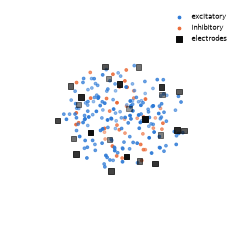

In [4]:
fig = plt.figure(figsize=(4.2, 4.2))
ax = fig.add_subplot(projection='3d')
p, e = reservoir.positions, reservoir.electrode_positions
ax.scatter(*p[reservoir.is_exc].T, s=8, color='#2a78d6', label='excitatory')
ax.scatter(*p[~reservoir.is_exc].T, s=8, color='#eb6834', label='inhibitory')
ax.scatter(*e.T, s=30, marker='s', color='#0b0b0b', label='electrodes')
ax.set_axis_off(); ax.legend(fontsize=7, frameon=False); plt.show()

## 3. Stimulate and record

One utterance becomes Poisson pulse trains on the electrodes. Each frame is held for 20 ms.

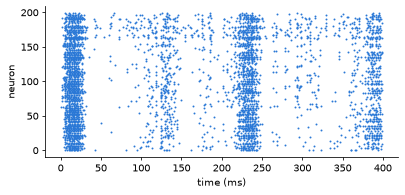

mean rate: 43.8 Hz
state tensor (batch, frames, neurons): (1, 20, 200)


In [5]:
X, lengths = pad_sequences([ds.X_train[0]])
stim = encoder.intensities(X)
out = reservoir.run(stim, record_spikes=True)
spikes = out['spikes'][0]
t, i = np.nonzero(spikes)
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.scatter(t, i, s=1, color='#2a78d6')
ax.set_xlabel('time (ms)'); ax.set_ylabel('neuron')
plt.show()
print('mean rate: %.1f Hz' % (spikes.mean() * 1000))
print('state tensor (batch, frames, neurons):', out['states'].shape)

## 4. Train a linear readout

Only the readout is trained. Per-frame filtered spike rates are pooled over the utterance (overall mean plus three temporal segments) and fed to logistic regression.

In [6]:
Xtr, ltr = pad_sequences(ds.X_train)
Xte, lte = pad_sequences(ds.X_test)
Ftr = pool_sequence_states(reservoir.transform(Xtr, ltr), ltr)
Fte = pool_sequence_states(reservoir.transform(Xte, lte), lte)
readout = train_logistic_readout(Ftr, ds.y_train)
print('feature matrix:', Ftr.shape)
print('test accuracy: %.3f' % accuracy(ds.y_test, readout.predict(Fte)))

feature matrix: (270, 800)
test accuracy: 0.951


## 5. Unsupervised STDP exposure

Replaying the training utterances with plasticity switched on changes the excitatory weights without using any labels. The readout is then retrained on the frozen network.

In [7]:
w0 = reservoir.W.copy()
reservoir.transform(Xtr, ltr, plastic=True, batch_size=30)
ne = reservoir.n_exc
change = np.linalg.norm(reservoir.W[:ne, :ne] - w0[:ne, :ne]) / np.linalg.norm(w0[:ne, :ne])
print('relative E->E weight change: %.2f' % change)
Ftr = pool_sequence_states(reservoir.transform(Xtr, ltr), ltr)
Fte = pool_sequence_states(reservoir.transform(Xte, lte), lte)
readout = train_logistic_readout(Ftr, ds.y_train)
print('test accuracy after STDP: %.3f' % accuracy(ds.y_test, readout.predict(Fte)))

relative E->E weight change: 0.25


test accuracy after STDP: 0.965


A single seed says little here: differences of this size are within seed-to-seed noise. See `report.md` for the five-seed comparison and the baselines.